In [1]:

# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Ignore Warnings
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:

# Load Dataset
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

# Display first 5 rows
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:

# Dataset Shape
print("Dataset Shape:", df.shape)

# Dataset Information
df.info()


Dataset Shape: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling

In [4]:
print("Total Rows", df.shape[0])
print("Total Column", df.shape[1])

Total Rows 7043
Total Column 21


In [5]:
print("\nColumn Name:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information")
print(df.info())


Column Name:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Dataset Information
<class 'pandas.core.frame.

In [6]:
df.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [7]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


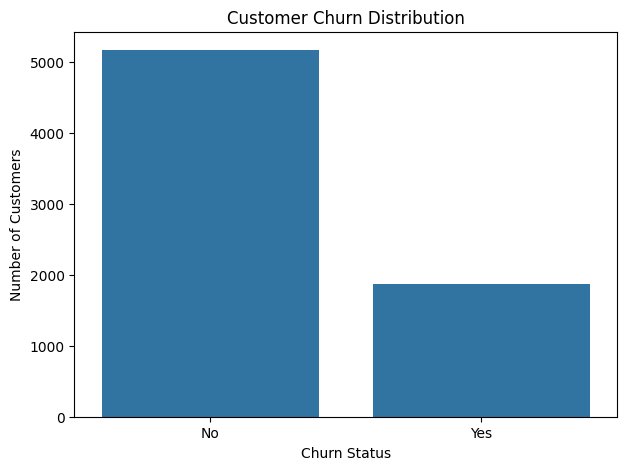

In [8]:

# Churn Distribution

print(df['Churn'].value_counts())

# Churn Percentage
print("\nChurn Percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)

# Visualization
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Churn')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')

plt.show()


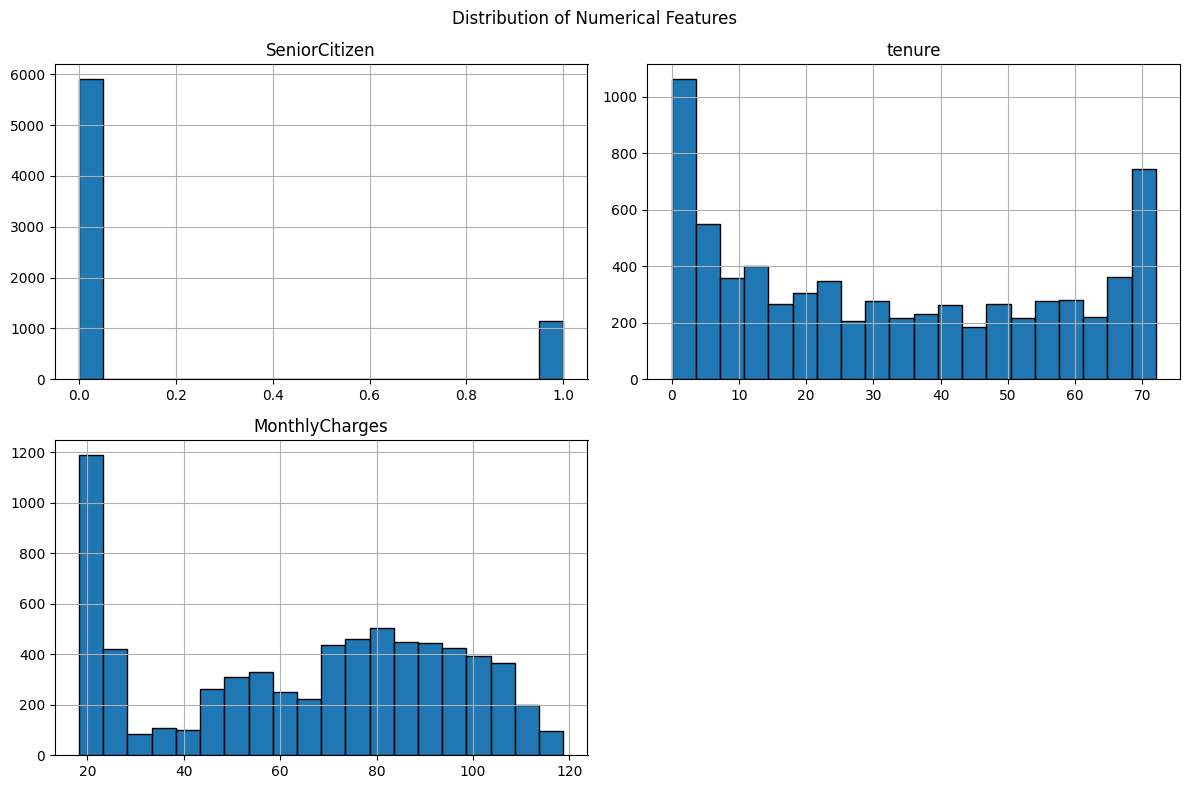

In [9]:

# Numerical Features

numerical_cols = df.select_dtypes(include=np.number).columns

df[numerical_cols].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical Features')
plt.tight_layout()
plt.show()


Categorical Columns:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']


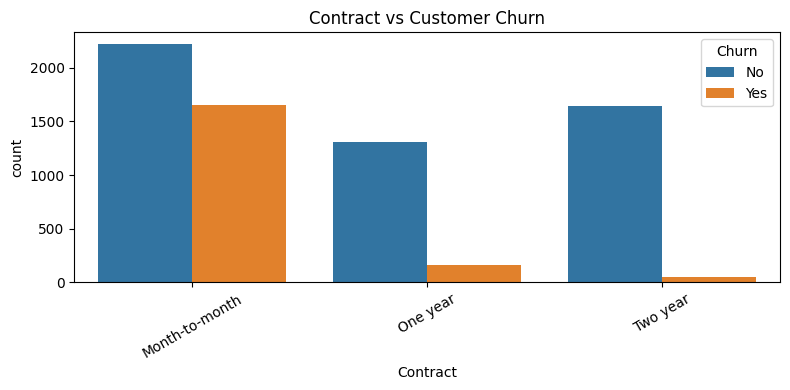

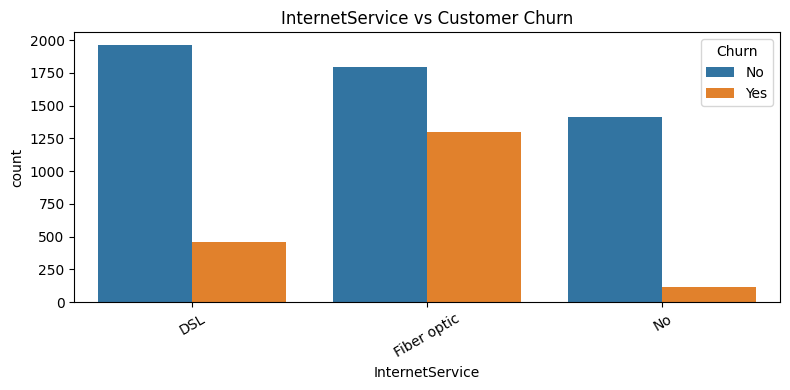

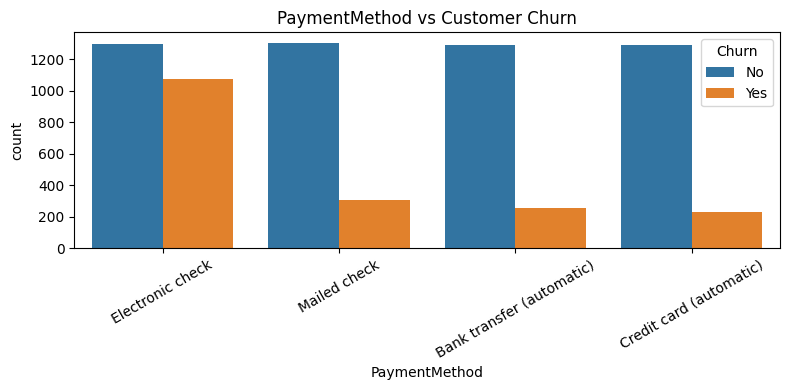

In [10]:

# Categorical Features

categorical_cols = df.select_dtypes(include='object').columns

print("Categorical Columns:")
print(categorical_cols.tolist())

# Visualize selected categorical features
for col in ['Contract', 'InternetService', 'PaymentMethod']:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col, hue='Churn')
    plt.title(f'{col} vs Customer Churn')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


In [11]:

# Remove Customer ID

df = df.drop('customerID', axis=1)

print("CustomerID column removed.")
print("Updated Dataset Shape:", df.shape)


CustomerID column removed.
Updated Dataset Shape: (7043, 20)


In [13]:

# Convert TotalCharges to Numeric

df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

# Check missing values
print(df.isnull().sum()[df.isnull().sum() > 0])


TotalCharges    11
dtype: int64


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [15]:

# 3.2 Missing Values Analysis

missing = df.isnull().sum()

print("Missing Values:")
print(missing[missing > 0])


Missing Values:
TotalCharges    11
dtype: int64


In [16]:
df['Churn'] = df['Churn'].map({
    'Yes': 1,
    'No': 0
})

print(df['Churn'].value_counts())

Churn
0    5174
1    1869
Name: count, dtype: int64


In [17]:

# One-Hot Encoding

df = pd.get_dummies(
    df,
    drop_first=True,
    dtype=int
)

print("Encoding Completed!")
print("Updated Dataset Shape:", df.shape)

display(df.head())


Encoding Completed!
Updated Dataset Shape: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


In [18]:
x = df.drop("Churn", axis=1)
y = df['Churn']

print("Features Shape:", x.shape)
print("Target Shape:", y.shape)


Features Shape: (7043, 30)
Target Shape: (7043,)


In [19]:

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", x_train.shape)
print("Testing Features:", x_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (5634, 30)
Testing Features: (1409, 30)
Training Target: (5634,)
Testing Target: (1409,)


In [20]:

from sklearn.preprocessing import StandardScaler

# Identify numerical columns
numerical_features = [
    col for col in x_train.columns
    if x_train[col].nunique() > 2
]

# Initialize Scaler
scaler = StandardScaler()

# Scale numerical features
x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()

x_train_scaled[numerical_features] = scaler.fit_transform(
    x_train[numerical_features]
)

x_test_scaled[numerical_features] = scaler.transform(
    x_test[numerical_features]
)

print("Feature Scaling Completed!")

print("Scaled Training Shape:", x_train_scaled.shape)
print("Scaled Testing Shape:", x_test_scaled.shape)


Feature Scaling Completed!
Scaled Training Shape: (5634, 30)
Scaled Testing Shape: (1409, 30)


In [21]:

# Check missing values in training data

print("NaN values in X_train:")
print(x_train.isnull().sum()[x_train.isnull().sum() > 0])

print("\nNaN values in X_train_scaled:")
print(x_train_scaled.isnull().sum()[x_train_scaled.isnull().sum() > 0])


NaN values in X_train:
TotalCharges    8
dtype: int64

NaN values in X_train_scaled:
TotalCharges    8
dtype: int64


In [23]:

x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()

x_train_scaled[numerical_features] = scaler.fit_transform(
    x_train[numerical_features]
)

x_test_scaled[numerical_features] = scaler.transform(
    x_test[numerical_features]
)

print("Feature Scaling Completed!")


Feature Scaling Completed!


In [24]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(x_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")


Logistic Regression Model Trained Successfully!


In [25]:

# Make Predictions
y_pred_lr = lr_model.predict(x_test_scaled)

print("Predictions Generated Successfully!")

# Compare Actual vs Predicted
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred_lr
})

display(results.head(10))


Predictions Generated Successfully!


,Actual,Predicted
0,0,0
1,0,1
2,0,0
3,0,0
4,0,0
5,0,1
6,0,0
7,0,0
8,0,0
9,1,0


In [26]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("LOGISTIC REGRESSION EVALUATION")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))


LOGISTIC REGRESSION EVALUATION
Accuracy: 0.8055358410220014
Precision: 0.6572327044025157
Recall: 0.5588235294117647
F1 Score: 0.6040462427745664

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



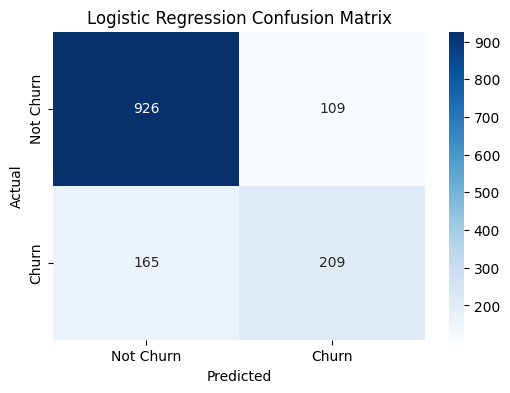

In [27]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Churn', 'Churn'],
    yticklabels=['Not Churn', 'Churn']
)

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [28]:

from sklearn.neighbors import KNeighborsClassifier

# Initialize KNN Model
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train Model
knn_model.fit(x_train_scaled, y_train)

print("KNN Model Trained Successfully!")


KNN Model Trained Successfully!


In [29]:

y_pred_knn = knn_model.predict(x_test_scaled)

print("KNN Predictions Generated Successfully!")


KNN Predictions Generated Successfully!


In [30]:

print("KNN MODEL EVALUATION")

print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print("Precision:", precision_score(y_test, y_pred_knn))
print("Recall:", recall_score(y_test, y_pred_knn))
print("F1 Score:", f1_score(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))


KNN MODEL EVALUATION
Accuracy: 0.7629524485450674
Precision: 0.553763440860215
Recall: 0.5508021390374331
F1 Score: 0.5522788203753352

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.84      0.84      1035
           1       0.55      0.55      0.55       374

    accuracy                           0.76      1409
   macro avg       0.70      0.70      0.70      1409
weighted avg       0.76      0.76      0.76      1409



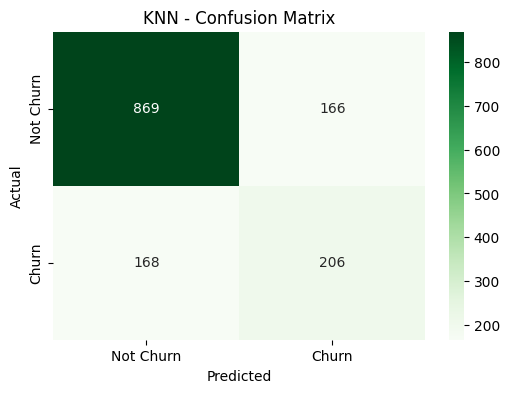

In [31]:

cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Not Churn', 'Churn'],
    yticklabels=['Not Churn', 'Churn']
)

plt.title('KNN - Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


In [32]:

# Model Comparison

comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'KNN'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_knn)
    ],
    'Precision': [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_knn)
    ],
    'Recall': [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_knn)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_knn)
    ]
})

display(comparison.round(4))


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040
1,KNN,0.7630,0.5538,0.5508,0.5523


In [33]:

# Training and Testing Accuracy Comparison

models = {
    'Logistic Regression': lr_model,
    'KNN': knn_model
}

for name, model in models.items():
    train_accuracy = model.score(x_train_scaled, y_train)
    test_accuracy = model.score(x_test_scaled, y_test)

    print(f"\n{name}")
    print("Training Accuracy:", round(train_accuracy, 4))
    print("Testing Accuracy:", round(test_accuracy, 4))
    print("Difference:", round(train_accuracy - test_accuracy, 4))



Logistic Regression
Training Accuracy: 0.8055
Testing Accuracy: 0.8055
Difference: -0.0001

KNN
Training Accuracy: 0.8342
Testing Accuracy: 0.763
Difference: 0.0713


## Overfitting vs Underfitting Analysis

Overfitting occurs when a model performs very well on training data but performs noticeably worse on unseen testing data.

Underfitting occurs when a model performs poorly on both training and testing data because it fails to learn the underlying patterns.

### Model Comparison

**Logistic Regression**
- Training Accuracy: 80.55%
- Testing Accuracy: 80.55%
- The nearly identical scores indicate good generalization.
- There is no clear evidence of overfitting.

**K-Nearest Neighbors (KNN)**
- Training Accuracy: 83.42%
- Testing Accuracy: 76.30%
- The difference of approximately 7.12 percentage points suggests some overfitting.
- The model performs better on training data than unseen testing data.

### Conclusion

Logistic Regression demonstrates more consistent performance on training and testing data. KNN shows signs of overfitting due to the difference between its training and testing accuracy.

Based on the evaluation results, Logistic Regression performs better than KNN on this dataset.

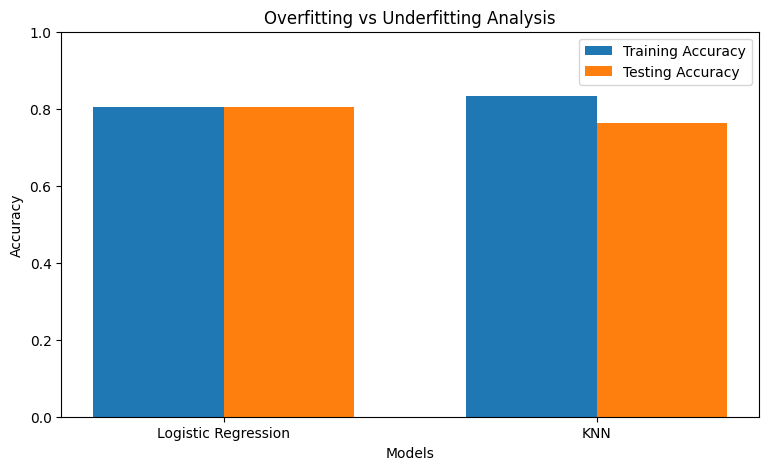

In [34]:

models = ['Logistic Regression', 'KNN']

train_scores = [0.8055, 0.8342]
test_scores = [0.8055, 0.7630]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, train_scores, width, label='Training Accuracy')
plt.bar(x + width/2, test_scores, width, label='Testing Accuracy')

plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.title('Overfitting vs Underfitting Analysis')

plt.xticks(x, models)
plt.ylim(0, 1)
plt.legend()
plt.show()


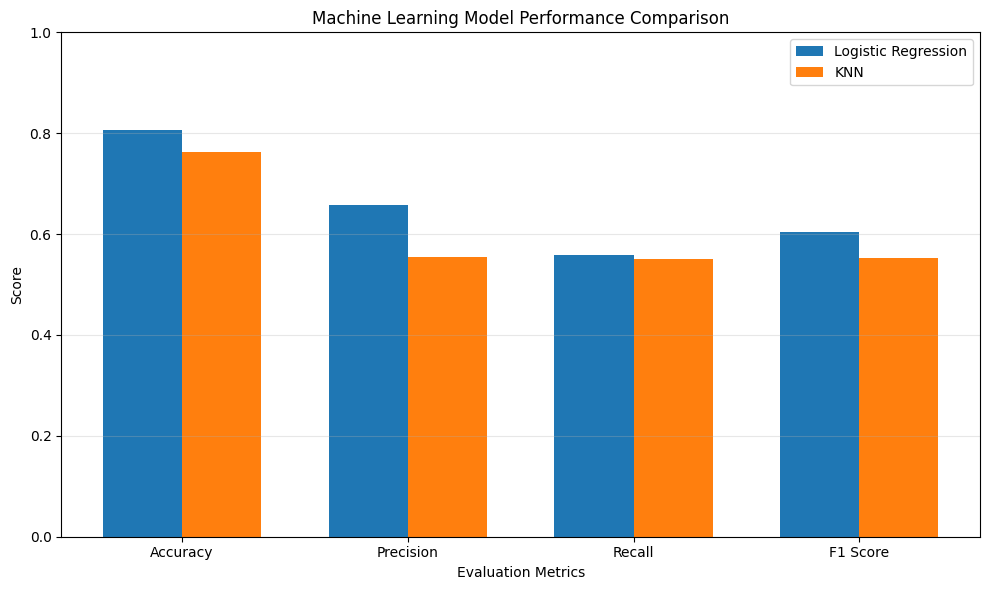

In [35]:

# Final Model Performance Comparison

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

lr_scores = [
    accuracy_score(y_test, y_pred_lr),
    precision_score(y_test, y_pred_lr),
    recall_score(y_test, y_pred_lr),
    f1_score(y_test, y_pred_lr)
]

knn_scores = [
    accuracy_score(y_test, y_pred_knn),
    precision_score(y_test, y_pred_knn),
    recall_score(y_test, y_pred_knn),
    f1_score(y_test, y_pred_knn)
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(x - width/2, lr_scores, width, label='Logistic Regression')
plt.bar(x + width/2, knn_scores, width, label='KNN')

plt.title('Machine Learning Model Performance Comparison')
plt.xlabel('Evaluation Metrics')
plt.ylabel('Score')
plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()
